# AirSense - 01 Exploratory Data Analysis
**Goal:** understand the data before modelling: class balance, missing values, differences between cities, seasonality, and why we split by *time*.

> Run from the project root (`jupyter notebook`). Needs `data/interim/city_day.csv` (created by `dvc repro`).

In [1]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from common import POLLUTANTS, CLASSES

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})
COLORS = {k: v["color"] for k, v in json.load(open("backend/health_advice.json")).items()}

df = pd.read_csv("data/interim/city_day.csv", parse_dates=["Date"])
quality = json.load(open("metrics/data_quality.json"))
print("DATA SOURCE:", quality["source"].upper(), "|", f"{len(df):,} rows,", df.City.nunique(), "cities,",
      df.Date.min().date(), "->", df.Date.max().date())
df.head()

DATA SOURCE: REAL | 29,531 rows, 26 cities, 2015-01-01 -> 2020-07-01


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


## 1. Data source
If the line above says **SYNTHETIC**, the project is running on generated demo data with the same schema as the Kaggle file. Put the real `city_day.csv` in `data/raw/` and run `dvc repro`; this notebook then re-runs unchanged on real data.

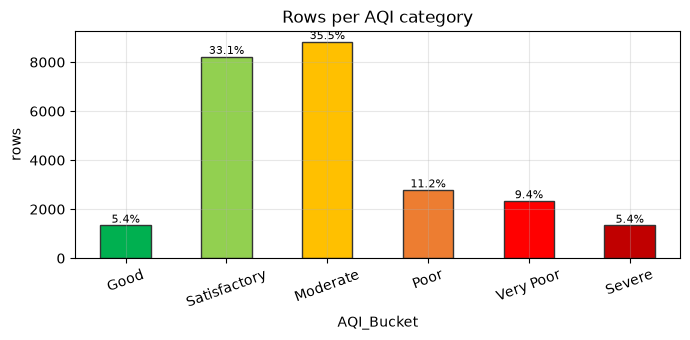

Rarest class: Severe (5.4%) -> accuracy alone would hide mistakes here, so we gate on macro-F1 and per-class recall.


In [2]:
counts = df["AQI_Bucket"].value_counts().reindex(CLASSES)
ax = counts.plot.bar(color=[COLORS[c] for c in CLASSES], figsize=(7, 3.5), edgecolor="#333")
ax.set_title("Rows per AQI category"); ax.set_ylabel("rows"); plt.xticks(rotation=20)
for i, v in enumerate(counts): ax.text(i, v, f"{v/counts.sum():.1%}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()
print("Rarest class:", counts.idxmin(), f"({counts.min()/counts.sum():.1%}) -> accuracy alone would hide mistakes here, so we gate on macro-F1 and per-class recall.")

## 2. Class balance
Some categories are much rarer than others. That is why the acceptance criteria use **macro-F1** and **recall for every class**.

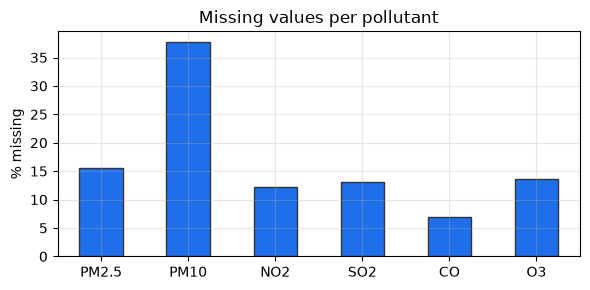

Rows with at least one pollutant missing: 44.4%


In [3]:
miss = (df[POLLUTANTS].isna().mean() * 100).round(2)
ax = miss.plot.bar(color="#1F6FEB", figsize=(6, 3), edgecolor="#333")
ax.set_ylabel("% missing"); ax.set_title("Missing values per pollutant"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print("Rows with at least one pollutant missing:", f"{df[POLLUTANTS].isna().any(axis=1).mean():.1%}")

## 3. Missing values
Real sensors fail. The pipeline fills blanks with the **city's median from the training period only**, and the API does the same at inference, so users may leave readings blank (at least 2 required).

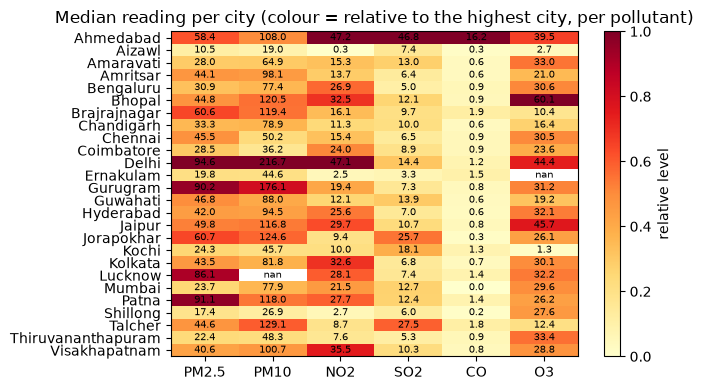

In [4]:
med = df.groupby("City")[POLLUTANTS].median()
norm = med / med.max()
fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(norm.values, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(POLLUTANTS)), POLLUTANTS); ax.set_yticks(range(len(med)), med.index); ax.grid(False)
for i in range(med.shape[0]):
    for j in range(med.shape[1]): ax.text(j, i, f"{med.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
ax.set_title("Median reading per city (colour = relative to the highest city, per pollutant)")
plt.colorbar(im, ax=ax, label="relative level"); plt.tight_layout(); plt.show()

## 4. Cities differ a lot
A 'normal' PM2.5 in one city is a pollution spike in another, which is why `city` is validated and used for imputation.

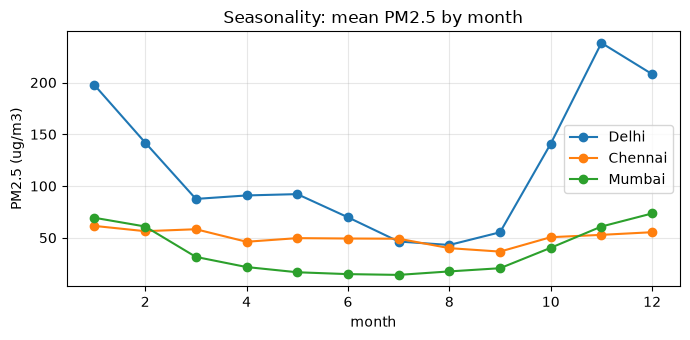

In [5]:
d = df.assign(month=df.Date.dt.month)
fig, ax = plt.subplots(figsize=(7, 3.5))
for city in [c for c in ["Delhi", "Chennai", "Mumbai"] if c in set(d.City)]:
    d[d.City == city].groupby("month")["PM2.5"].mean().plot(ax=ax, marker="o", label=city)
ax.set_title("Seasonality: mean PM2.5 by month"); ax.set_xlabel("month"); ax.set_ylabel("PM2.5 (ug/m3)"); ax.legend(); plt.tight_layout(); plt.show()

## 5. Seasonality
Winter months are worse, so `month` is a model feature (and the UI asks for a date).

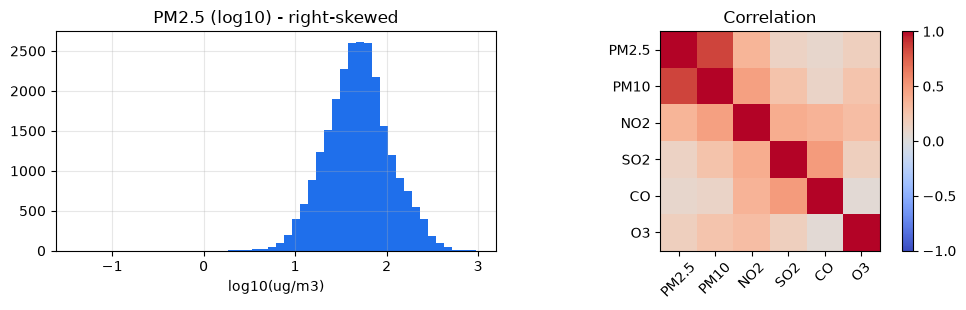

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
d["PM2.5"].dropna().pipe(np.log10).hist(bins=50, ax=axes[0], color="#1F6FEB"); axes[0].set_title("PM2.5 (log10) - right-skewed"); axes[0].set_xlabel("log10(ug/m3)")
corr = d[POLLUTANTS].corr()
im = axes[1].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1); axes[1].grid(False)
axes[1].set_xticks(range(6), POLLUTANTS, rotation=45); axes[1].set_yticks(range(6), POLLUTANTS); axes[1].set_title("Correlation")
plt.colorbar(im, ax=axes[1]); plt.tight_layout(); plt.show()

## 6. Distributions and correlation
Readings are right-skewed (a few extreme days), so we clip at the 99.9th training percentile instead of deleting rows.

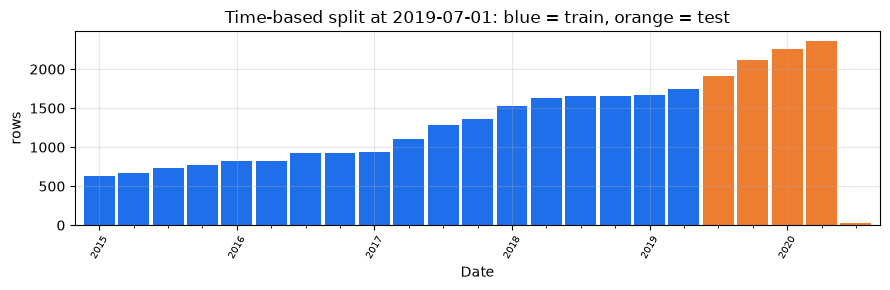

train rows: 20,851  |  test rows (future): 8,680


In [7]:
import yaml
cutoff = pd.Timestamp(yaml.safe_load(open("params.yaml"))["preprocess"]["test_cutoff_date"])
per_year = df.groupby(df.Date.dt.to_period("Q")).size()
colors = ["#1F6FEB" if p.start_time < cutoff else "#ED7D31" for p in per_year.index]
ax = per_year.plot.bar(color=colors, figsize=(9, 3), width=.9); ax.set_title(f"Time-based split at {cutoff.date()}: blue = train, orange = test"); ax.set_ylabel("rows"); plt.xticks(rotation=60, fontsize=7); plt.tight_layout(); plt.show()
print(f"train rows: {(df.Date < cutoff).sum():,}  |  test rows (future): {(df.Date >= cutoff).sum():,}")

## 7. Why a time-based split?
A random split would put neighbouring days (almost identical pollution) in both train and test, inflating scores. We train on the past and test on the **future**, which is how the app is used.

## Take-aways
* Classes are imbalanced -> macro-F1 and per-class recall are the gates.
* Missing values are common -> per-city median imputation, reported back to the user.
* Strong city and seasonal effects -> `month` feature and city validation.
* Official AQI is a formula of these same pollutants, so high accuracy is expected (see the next notebook for a concrete check).